In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!nvidia-smi

Tue Nov 10 02:45:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!wget https://bitbucket.org/ishaanjav/code-and-deploy-custom-tensorflow-lite-model/raw/a4febbfee178324b2083e322cdead7465d6fdf95/fruits.zip


--2026-11-10 02:45:45--  https://bitbucket.org/ishaanjav/code-and-deploy-custom-tensorflow-lite-model/raw/a4febbfee178324b2083e322cdead7465d6fdf95/fruits.zip
Resolving bitbucket.org (bitbucket.org)... 104.192.142.24, 104.192.142.25, 104.192.142.26, ...
Connecting to bitbucket.org (bitbucket.org)|104.192.142.24|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-10 02:45:45 ERROR 404: Not Found.



In [5]:
!unzip fruits.zip

Archive:  fruits.zip
   creating: fruits/
  inflating: __MACOSX/._fruits       
  inflating: fruits/.DS_Store        
  inflating: __MACOSX/fruits/._.DS_Store  
   creating: fruits/test/
   creating: fruits/train/
   creating: fruits/validation/
   creating: fruits/test/apple/
  inflating: fruits/test/.DS_Store   
  inflating: __MACOSX/fruits/test/._.DS_Store  
   creating: fruits/test/banana/
   creating: fruits/test/orange/
   creating: fruits/train/apple/
  inflating: fruits/train/.DS_Store  
  inflating: __MACOSX/fruits/train/._.DS_Store  
   creating: fruits/train/banana/
   creating: fruits/train/orange/
   creating: fruits/validation/apple/
  inflating: fruits/validation/.DS_Store  
  inflating: __MACOSX/fruits/validation/._.DS_Store  
   creating: fruits/validation/banana/
   creating: fruits/validation/orange/
  inflating: fruits/test/apple/Screen Shot 2018-06-08 at 5.27.19 PM.png  
  inflating: __MACOSX/fruits/test/apple/._Screen Shot 2018-06-08 at 5.27.19 PM.png  
  inflatin

In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [7]:
tf.__version__

'2.21.0'

In [8]:
img_height, img_width= 32,32
batch_size= 32

train_ds=tf.keras.utils.image_dataset_from_directory(
    "fruits/train",
    image_size=(img_height, img_width),
    batch_size=batch_size,
)
val_ds=tf.keras.utils.image_dataset_from_directory(
    "fruits/validation",
    image_size=(img_height, img_width),
    batch_size=batch_size,
)
test_ds=tf.keras.utils.image_dataset_from_directory(
    "fruits/test",
    image_size=(img_height, img_width),
    batch_size=batch_size,
)

Found 460 files belonging to 3 classes.
Found 66 files belonging to 3 classes.
Found 130 files belonging to 3 classes.


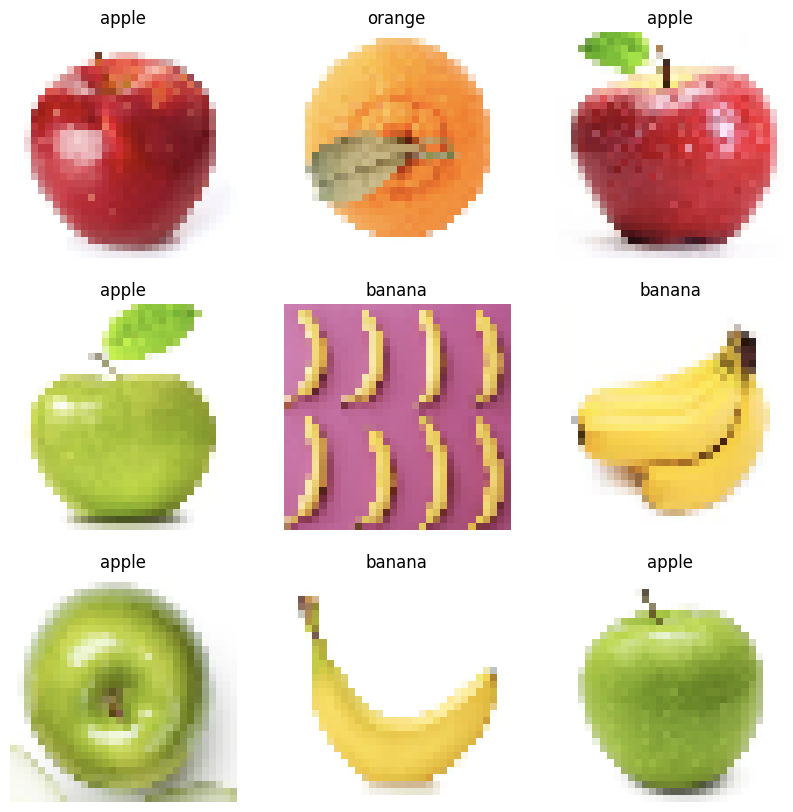

In [9]:
class_names=["apple","banana","orange"]
plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):
 for i in range(9):
  ax=plt.subplot(3, 3, i + 1)
  plt.imshow(images[i].numpy().astype("uint8"))
  plt.title(class_names[labels[i]])
  plt.axis("off")

In [10]:
model=tf.keras.Sequential(
    [
        tf.keras.layers.Rescaling(1./2),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="softmax"),
        tf.keras.layers.Dense(3)
    ]
)

In [11]:
model.compile(
    optimizer="rmsprop",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)

In [12]:
model.fit(train_ds, validation_data=val_ds, epochs=20)

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 21s 852ms/step - accuracy: 0.3543 - loss: 1.1011 - val_accuracy: 0.3485 - val_loss: 1.1009
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 0.3522 - loss: 1.1006 - val_accuracy: 0.3485 - val_loss: 1.1003
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.3522 - loss: 1.1002 - val_accuracy: 0.3485 - val_loss: 1.0999
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.3522 - loss: 1.0997 - val_accuracy: 0.3485 - val_loss: 1.0995
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 105ms/step - accuracy: 0.3522 - loss: 1.0995 - val_accuracy: 0.3485 - val_loss: 1.0992
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 171ms/step - accuracy: 0.3522 - loss: 1.0990 - val_accuracy: 0.3485 - val_loss: 1.0989
Epoch 7/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 104ms/step - accuracy: 0.3522 - loss: 1.0988 - val_accuracy: 0.3485 - val_loss: 1.0987
Epoch 8/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.3522 - loss: 1.0986 - val_accuracy: 0.34

In [13]:
model.evaluate(test_ds)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.3615 - loss: 1.0969


[1.0968704223632812, 0.36153846979141235]

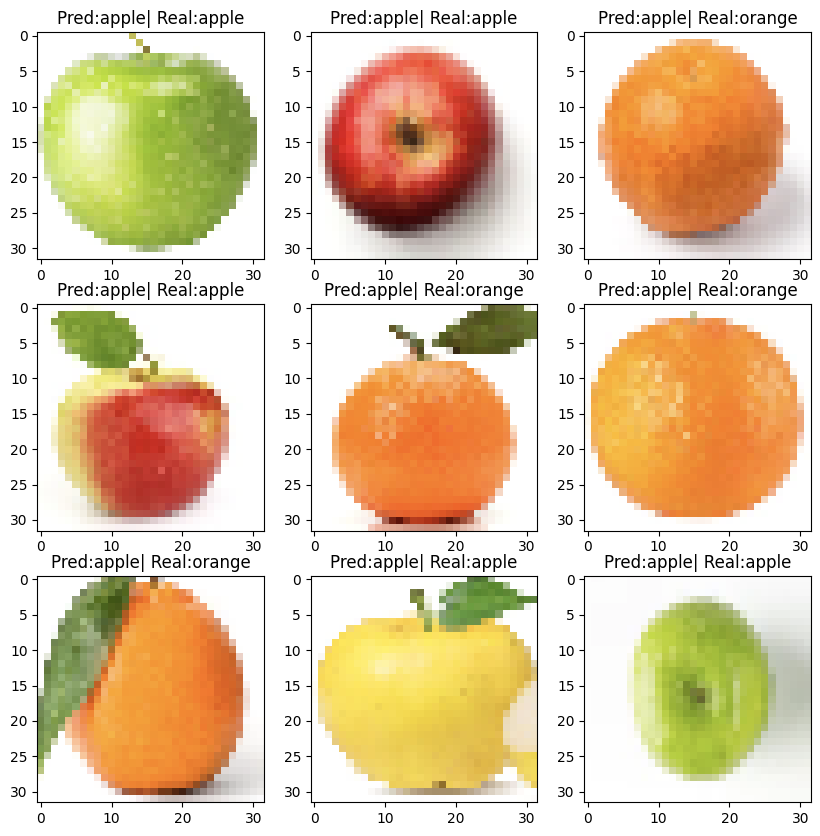

In [14]:
import numpy

plt.figure(figsize=(10,10))
for images, labels in test_ds.take(1):
  classifications=model(images)
  #print(classifications)

  for i in range(9):
    ax=plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    index=numpy.argmax(classifications[i])
    plt.title("Pred:" + class_names[index] + "| Real:" + class_names[labels[i]])

In [15]:
convertor=tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model=convertor.convert()

with open("model.tflite", "wb") as f:
  f.write(tflite_model)


Saved artifact at '/tmp/tmpd24o0gdm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  137950834165712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950834179728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950793482320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950793482512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950834179536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950793482704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950793483664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950793484048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950793483472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137950793484240: TensorSpec(shape=(), dtype=tf.resource, name=None)
